
STEP 6 MODEL FITTING: 1 arcmin

MODEL 1: SUN-CENTERED CIRCLE
Radius: 1.5261874744948327 AU

MODEL 2: FREE-CENTER CIRCLE
Center x: -0.09834340707483001 AU
Center y: 0.0199387745133352 AU
Radius: 1.4844490208763563 AU

MODEL 3: KEPLER ELLIPSE
Semi-latus rectum p: 1.4788259971952848 AU
Eccentricity e: 0.06688787385304451
Orientation omega: -12.633619244501244 degrees
Semi-major axis a: 1.4854719805181453 AU
Semi-minor axis b: 1.482145263763104 AU

--------------------------------------------
GEOMETRIC ERROR COMPARISON
--------------------------------------------

Sun-centered circle:
{'RMSE_AU': 0.05150414998493264, 'MAE_AU': 0.04684849153155701, 'Median_Error_AU': 0.04234996441210641, 'Max_Error_AU': 0.09938497203449416}

Free-center circle:
{'RMSE_AU': 0.021718489276362128, 'MAE_AU': 0.017068369458604786, 'Median_Error_AU': 0.012947792293663898, 'Max_Error_AU': 0.049115963183759645}

Ellipse:
{'RMSE_AU': 0.021759296418067096, 'MAE_AU': 0.01712384361766672, 'Median_Error_AU': 0.01316140

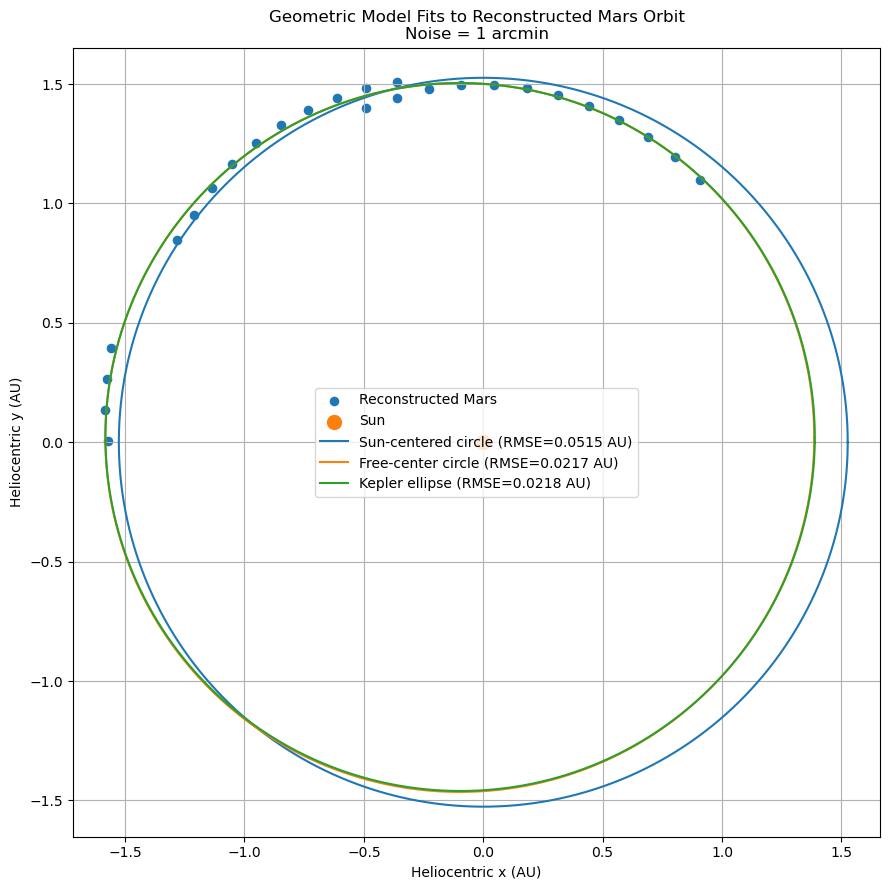


STEP 6 MODEL FITTING: 2 arcmin

MODEL 1: SUN-CENTERED CIRCLE
Radius: 1.526137637933633 AU

MODEL 2: FREE-CENTER CIRCLE
Center x: -0.0985351397293879 AU
Center y: 0.02015513006852991 AU
Radius: 1.4841854970622987 AU

MODEL 3: KEPLER ELLIPSE
Semi-latus rectum p: 1.4785489299746566 AU
Eccentricity e: 0.06704517188305026
Orientation omega: -12.729362004552918 degrees
Semi-major axis a: 1.4852250985883573 AU
Semi-minor axis b: 1.4818832546085807 AU

--------------------------------------------
GEOMETRIC ERROR COMPARISON
--------------------------------------------

Sun-centered circle:
{'RMSE_AU': 0.051629497870732885, 'MAE_AU': 0.04696296549003668, 'Median_Error_AU': 0.04216471772697247, 'Max_Error_AU': 0.09991615920760966}

Free-center circle:
{'RMSE_AU': 0.02187881543544818, 'MAE_AU': 0.017223966021513087, 'Median_Error_AU': 0.01252143258215243, 'Max_Error_AU': 0.04846256436041291}

Ellipse:
{'RMSE_AU': 0.021919957262296584, 'MAE_AU': 0.01726767467343622, 'Median_Error_AU': 0.0127397765

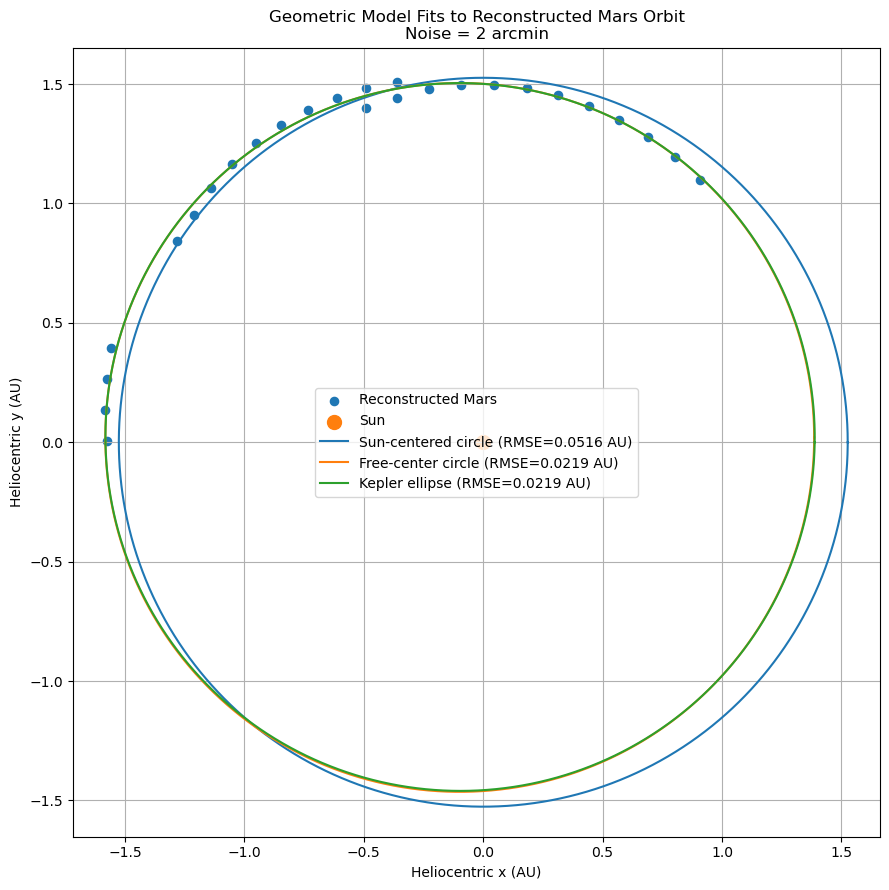


STEP 6 MODEL FITTING: 5 arcmin

MODEL 1: SUN-CENTERED CIRCLE
Radius: 1.5259718469240913 AU

MODEL 2: FREE-CENTER CIRCLE
Center x: -0.09908353421875307 AU
Center y: 0.020794000143921652 AU
Radius: 1.4833928396533402 AU

MODEL 3: KEPLER ELLIPSE
Semi-latus rectum p: 1.477719682696691 AU
Eccentricity e: 0.06749884868565244
Orientation omega: -13.010676643943214 degrees
Semi-major axis a: 1.4844831282222133 AU
Semi-minor axis b: 1.481097544797479 AU

--------------------------------------------
GEOMETRIC ERROR COMPARISON
--------------------------------------------

Sun-centered circle:
{'RMSE_AU': 0.05202725137441393, 'MAE_AU': 0.04730017180309114, 'Median_Error_AU': 0.043519589639412826, 'Max_Error_AU': 0.10150125039193446}

Free-center circle:
{'RMSE_AU': 0.0224313370838686, 'MAE_AU': 0.01772099555691596, 'Median_Error_AU': 0.012080158603314066, 'Max_Error_AU': 0.04652943164427775}

Ellipse:
{'RMSE_AU': 0.0224746952569711, 'MAE_AU': 0.01775976590522289, 'Median_Error_AU': 0.011934089555

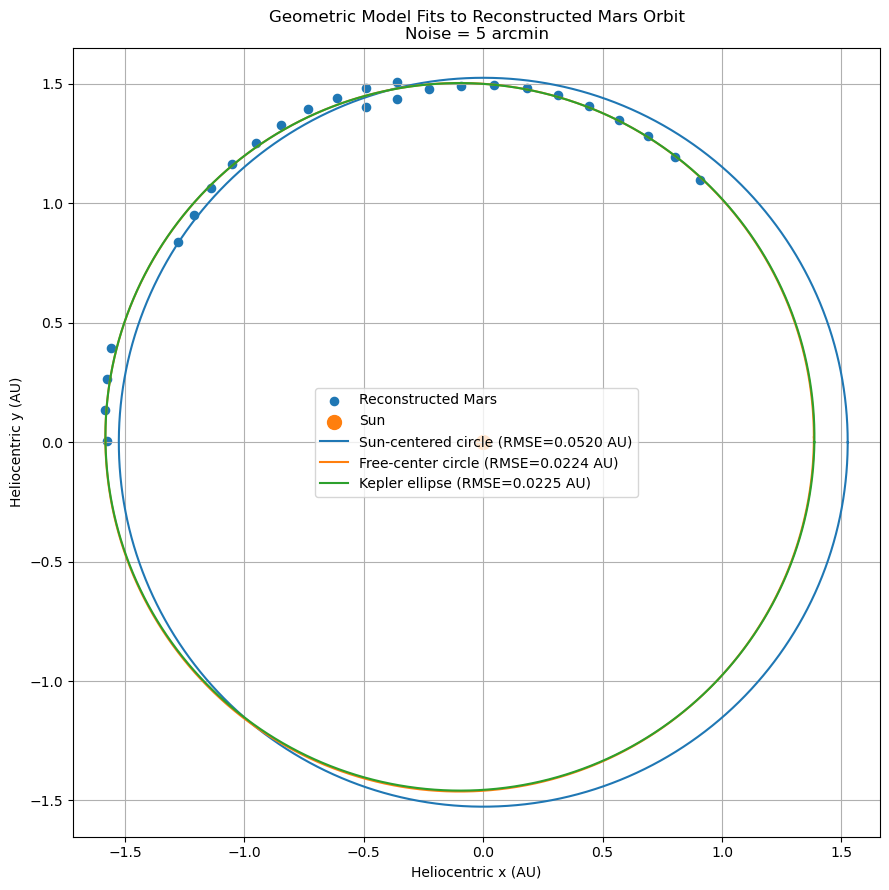



FINAL MODEL COMPARISON

 Noise_arcmin               Model  RMSE_AU   MAE_AU  Median_Error_AU  Max_Error_AU
            1  Free-center circle 0.021718 0.017068         0.012948      0.049116
            1      Kepler ellipse 0.021759 0.017124         0.013161      0.048913
            1 Sun-centered circle 0.051504 0.046848         0.042350      0.099385
            2  Free-center circle 0.021879 0.017224         0.012521      0.048463
            2      Kepler ellipse 0.021920 0.017268         0.012740      0.048260
            2 Sun-centered circle 0.051629 0.046963         0.042165      0.099916
            5  Free-center circle 0.022431 0.017721         0.012080      0.046529
            5      Kepler ellipse 0.022475 0.017760         0.011934      0.046580
            5 Sun-centered circle 0.052027 0.047300         0.043520      0.101501

Saved model_fit_summary.csv


In [1]:
"""
fit_models_step6.py

Homework 1.1 - Step 6

Fit three geometric models to reconstructed Mars positions:

    1. Circle centered at the Sun
    2. Circle with arbitrary center
    3. Kepler ellipse with the Sun at one focus

Then compare all three using the SAME geometric error:
distance from each reconstructed point to the fitted curve.

Input:
    mars_reconstructed_1arcmin.csv
    mars_reconstructed_2arcmin.csv
    mars_reconstructed_5arcmin.csv

Output:
    model_fit_summary.csv

    model_fits_1arcmin.png
    model_fits_2arcmin.png
    model_fits_5arcmin.png
"""

import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import least_squares
from scipy.spatial import cKDTree


# ============================================================
# 1. NUMBER OF POINTS USED TO DRAW EACH FITTED CURVE
# ============================================================

CURVE_POINTS = 10000


# ============================================================
# 2. LOAD RECONSTRUCTED MARS DATA
# ============================================================

def load_reconstruction(noise_arcmin):

    filename = (
        f"mars_reconstructed_"
        f"{noise_arcmin}arcmin.csv"
    )

    df = pd.read_csv(filename)

    x = df["x_AU"].to_numpy()
    y = df["y_AU"].to_numpy()

    return df, x, y


# ============================================================
# 3. MODEL 1:
#    CIRCLE CENTERED AT THE SUN
# ============================================================

def fit_sun_centered_circle(x, y):
    """
    Model:

        x^2 + y^2 = R^2

    Since the center is fixed at the Sun (0,0),
    the only parameter is R.

    The least-squares radial estimate is the mean
    heliocentric radius.
    """

    r = np.sqrt(
        x**2 + y**2
    )

    R = np.mean(r)

    return R


def sample_sun_centered_circle(R):

    theta = np.linspace(
        0,
        2 * np.pi,
        CURVE_POINTS
    )

    x_curve = (
        R * np.cos(theta)
    )

    y_curve = (
        R * np.sin(theta)
    )

    return x_curve, y_curve


# ============================================================
# 4. MODEL 2:
#    CIRCLE WITH ARBITRARY CENTER
# ============================================================

def free_circle_residuals(
    params,
    x,
    y
):
    """
    Geometric circle residual:

        sqrt((x-h)^2 + (y-k)^2) - R

    Parameters:
        h = x-coordinate of center
        k = y-coordinate of center
        R = radius
    """

    h, k, R = params

    distances = np.sqrt(
        (x - h)**2
        +
        (y - k)**2
    )

    return (
        distances - R
    )


def fit_free_circle(x, y):

    # Initial guess:
    # center near average data location,
    # radius based on average distance.
    h0 = np.mean(x)
    k0 = np.mean(y)

    R0 = np.mean(
        np.sqrt(
            (x - h0)**2
            +
            (y - k0)**2
        )
    )

    result = least_squares(
        free_circle_residuals,

        x0=[
            h0,
            k0,
            R0
        ],

        args=(
            x,
            y
        ),

        # Radius must remain positive.
        bounds=(
            [
                -5.0,
                -5.0,
                0.01
            ],
            [
                5.0,
                5.0,
                5.0
            ]
        )
    )

    h, k, R = result.x

    return h, k, R


def sample_free_circle(
    h,
    k,
    R
):

    theta = np.linspace(
        0,
        2 * np.pi,
        CURVE_POINTS
    )

    x_curve = (
        h
        +
        R * np.cos(theta)
    )

    y_curve = (
        k
        +
        R * np.sin(theta)
    )

    return x_curve, y_curve


# ============================================================
# 5. MODEL 3:
#    KEPLER ELLIPSE WITH SUN AT ONE FOCUS
# ============================================================
#
# Polar equation:
#
#       r(theta)
#       =
#       p / (1 + e cos(theta - omega))
#
# where
#
#       p     = semi-latus rectum
#       e     = eccentricity
#       omega = orientation of perihelion
#
# For an ellipse:
#
#       0 <= e < 1
#
# and
#
#       a = p / (1 - e^2)
#
# ============================================================

def kepler_ellipse_residuals(
    params,
    theta,
    r_observed
):

    p, e, omega = params

    denominator = (
        1
        +
        e
        * np.cos(
            theta - omega
        )
    )

    r_model = (
        p
        /
        denominator
    )

    return (
        r_observed
        -
        r_model
    )


def fit_kepler_ellipse(
    x,
    y
):

    # Convert reconstructed Cartesian points
    # into polar coordinates around the Sun.

    theta = np.arctan2(
        y,
        x
    )

    r = np.sqrt(
        x**2
        +
        y**2
    )

    # Initial guess:
    #
    # p roughly around average Mars radius
    #
    # small but nonzero eccentricity
    #
    # orientation initially zero

    p0 = np.median(r)

    e0 = 0.05

    omega0 = 0.0

    result = least_squares(
        kepler_ellipse_residuals,

        x0=[
            p0,
            e0,
            omega0
        ],

        args=(
            theta,
            r
        ),

        bounds=(
            [
                0.5,
                0.0,
                -2 * np.pi
            ],
            [
                3.0,
                0.95,
                2 * np.pi
            ]
        )
    )

    p, e, omega = result.x

    # Convert p,e into familiar ellipse quantities.

    a = (
        p
        /
        (1 - e**2)
    )

    b = (
        a
        * np.sqrt(
            1 - e**2
        )
    )

    focus_distance = (
        a * e
    )

    return {
        "p": p,
        "e": e,
        "omega": omega,
        "a": a,
        "b": b,
        "focus_distance": focus_distance
    }


def sample_kepler_ellipse(
    p,
    e,
    omega
):

    theta = np.linspace(
        0,
        2 * np.pi,
        CURVE_POINTS
    )

    r = (
        p
        /
        (
            1
            +
            e
            * np.cos(
                theta - omega
            )
        )
    )

    x_curve = (
        r
        * np.cos(theta)
    )

    y_curve = (
        r
        * np.sin(theta)
    )

    return (
        x_curve,
        y_curve
    )


# ============================================================
# 6. COMMON GEOMETRIC RESIDUAL
# ============================================================
#
# This is important.
#
# The three models are fitted differently, but for the FINAL
# comparison we evaluate them using exactly the same quantity:
#
#      Euclidean distance from each reconstructed point
#      to the nearest point on the fitted curve.
#
# That makes the RMSE values directly comparable.
# ============================================================

def geometric_errors(
    data_x,
    data_y,
    curve_x,
    curve_y
):

    curve_points = np.column_stack(
        [
            curve_x,
            curve_y
        ]
    )

    data_points = np.column_stack(
        [
            data_x,
            data_y
        ]
    )

    tree = cKDTree(
        curve_points
    )

    distances, _ = tree.query(
        data_points
    )

    return distances


# ============================================================
# 7. ERROR STATISTICS
# ============================================================

def error_statistics(
    errors
):

    rmse = np.sqrt(
        np.mean(
            errors**2
        )
    )

    mae = np.mean(
        np.abs(errors)
    )

    median = np.median(
        np.abs(errors)
    )

    maximum = np.max(
        np.abs(errors)
    )

    return {
        "RMSE_AU": rmse,
        "MAE_AU": mae,
        "Median_Error_AU": median,
        "Max_Error_AU": maximum
    }


# ============================================================
# 8. FIT ALL THREE MODELS
# ============================================================

def fit_all_models(
    noise_arcmin
):

    print(
        "\n"
        "============================================"
    )

    print(
        f"STEP 6 MODEL FITTING: "
        f"{noise_arcmin} arcmin"
    )

    print(
        "============================================"
    )

    df, x, y = load_reconstruction(
        noise_arcmin
    )

    # ========================================================
    # MODEL 1
    # ========================================================

    R_sun = (
        fit_sun_centered_circle(
            x,
            y
        )
    )

    (
        sun_circle_x,
        sun_circle_y
    ) = sample_sun_centered_circle(
        R_sun
    )

    sun_errors = geometric_errors(
        x,
        y,
        sun_circle_x,
        sun_circle_y
    )

    sun_stats = error_statistics(
        sun_errors
    )


    # ========================================================
    # MODEL 2
    # ========================================================

    (
        h,
        k,
        R_free
    ) = fit_free_circle(
        x,
        y
    )

    (
        free_circle_x,
        free_circle_y
    ) = sample_free_circle(
        h,
        k,
        R_free
    )

    free_errors = geometric_errors(
        x,
        y,
        free_circle_x,
        free_circle_y
    )

    free_stats = error_statistics(
        free_errors
    )


    # ========================================================
    # MODEL 3
    # ========================================================

    ellipse = fit_kepler_ellipse(
        x,
        y
    )

    (
        ellipse_x,
        ellipse_y
    ) = sample_kepler_ellipse(
        ellipse["p"],
        ellipse["e"],
        ellipse["omega"]
    )

    ellipse_errors = geometric_errors(
        x,
        y,
        ellipse_x,
        ellipse_y
    )

    ellipse_stats = error_statistics(
        ellipse_errors
    )


    # ========================================================
    # PRINT FITTED PARAMETERS
    # ========================================================

    print(
        "\nMODEL 1: SUN-CENTERED CIRCLE"
    )

    print(
        "Radius:",
        R_sun,
        "AU"
    )


    print(
        "\nMODEL 2: FREE-CENTER CIRCLE"
    )

    print(
        "Center x:",
        h,
        "AU"
    )

    print(
        "Center y:",
        k,
        "AU"
    )

    print(
        "Radius:",
        R_free,
        "AU"
    )


    print(
        "\nMODEL 3: KEPLER ELLIPSE"
    )

    print(
        "Semi-latus rectum p:",
        ellipse["p"],
        "AU"
    )

    print(
        "Eccentricity e:",
        ellipse["e"]
    )

    print(
        "Orientation omega:",
        math.degrees(
            ellipse["omega"]
        ),
        "degrees"
    )

    print(
        "Semi-major axis a:",
        ellipse["a"],
        "AU"
    )

    print(
        "Semi-minor axis b:",
        ellipse["b"],
        "AU"
    )


    # ========================================================
    # PRINT ERRORS
    # ========================================================

    print(
        "\n--------------------------------------------"
    )

    print(
        "GEOMETRIC ERROR COMPARISON"
    )

    print(
        "--------------------------------------------"
    )

    print(
        "\nSun-centered circle:"
    )

    print(
        sun_stats
    )

    print(
        "\nFree-center circle:"
    )

    print(
        free_stats
    )

    print(
        "\nEllipse:"
    )

    print(
        ellipse_stats
    )


    # ========================================================
    # CREATE COMPARISON TABLE
    # ========================================================

    rows = []

    rows.append({
        "Noise_arcmin":
            noise_arcmin,

        "Model":
            "Sun-centered circle",

        "RMSE_AU":
            sun_stats["RMSE_AU"],

        "MAE_AU":
            sun_stats["MAE_AU"],

        "Median_Error_AU":
            sun_stats[
                "Median_Error_AU"
            ],

        "Max_Error_AU":
            sun_stats[
                "Max_Error_AU"
            ],

        "Parameter_1":
            R_sun,

        "Parameter_2":
            np.nan,

        "Parameter_3":
            np.nan
    })


    rows.append({
        "Noise_arcmin":
            noise_arcmin,

        "Model":
            "Free-center circle",

        "RMSE_AU":
            free_stats["RMSE_AU"],

        "MAE_AU":
            free_stats["MAE_AU"],

        "Median_Error_AU":
            free_stats[
                "Median_Error_AU"
            ],

        "Max_Error_AU":
            free_stats[
                "Max_Error_AU"
            ],

        "Parameter_1":
            h,

        "Parameter_2":
            k,

        "Parameter_3":
            R_free
    })


    rows.append({
        "Noise_arcmin":
            noise_arcmin,

        "Model":
            "Kepler ellipse",

        "RMSE_AU":
            ellipse_stats["RMSE_AU"],

        "MAE_AU":
            ellipse_stats["MAE_AU"],

        "Median_Error_AU":
            ellipse_stats[
                "Median_Error_AU"
            ],

        "Max_Error_AU":
            ellipse_stats[
                "Max_Error_AU"
            ],

        "Parameter_1":
            ellipse["a"],

        "Parameter_2":
            ellipse["e"],

        "Parameter_3":
            math.degrees(
                ellipse["omega"]
            )
    })


    # ========================================================
    # PLOT ALL THREE MODELS
    # ========================================================

    plt.figure(
        figsize=(9, 9)
    )

    # Reconstructed observations
    plt.scatter(
        x,
        y,
        s=35,
        label="Reconstructed Mars"
    )

    # Sun
    plt.scatter(
        [0],
        [0],
        s=100,
        marker="o",
        label="Sun"
    )

    # Model 1
    plt.plot(
        sun_circle_x,
        sun_circle_y,
        label=(
            "Sun-centered circle "
            f"(RMSE={sun_stats['RMSE_AU']:.4f} AU)"
        )
    )

    # Model 2
    plt.plot(
        free_circle_x,
        free_circle_y,
        label=(
            "Free-center circle "
            f"(RMSE={free_stats['RMSE_AU']:.4f} AU)"
        )
    )

    # Model 3
    plt.plot(
        ellipse_x,
        ellipse_y,
        label=(
            "Kepler ellipse "
            f"(RMSE={ellipse_stats['RMSE_AU']:.4f} AU)"
        )
    )

    plt.xlabel(
        "Heliocentric x (AU)"
    )

    plt.ylabel(
        "Heliocentric y (AU)"
    )

    plt.title(
        "Geometric Model Fits to "
        "Reconstructed Mars Orbit\n"
        f"Noise = {noise_arcmin} arcmin"
    )

    plt.axis(
        "equal"
    )

    plt.grid(
        True
    )

    plt.legend()

    plt.tight_layout()

    plt.savefig(
        f"model_fits_"
        f"{noise_arcmin}arcmin.png",
        dpi=300
    )

    plt.show()


    return pd.DataFrame(
        rows
    )


# ============================================================
# 9. RUN 1', 2', 5' DATASETS
# ============================================================

def main():

    all_results = []

    for noise in [
        1,
        2,
        5
    ]:

        results = fit_all_models(
            noise
        )

        all_results.append(
            results
        )

    summary = pd.concat(
        all_results,
        ignore_index=True
    )

    # Sort by noise and RMSE
    summary = summary.sort_values(
        [
            "Noise_arcmin",
            "RMSE_AU"
        ]
    )

    print(
        "\n\n"
        "============================================"
    )

    print(
        "FINAL MODEL COMPARISON"
    )

    print(
        "============================================\n"
    )

    print(
        summary[
            [
                "Noise_arcmin",
                "Model",
                "RMSE_AU",
                "MAE_AU",
                "Median_Error_AU",
                "Max_Error_AU"
            ]
        ].to_string(
            index=False
        )
    )

    summary.to_csv(
        "model_fit_summary.csv",
        index=False
    )

    print(
        "\nSaved model_fit_summary.csv"
    )


if __name__ == "__main__":
    main()

The Sun-centered circular model was clearly inconsistent with the reconstructed positions, with an RMSE of approximately \(0.052\) AU compared with approximately \(0.022\) AU for the other models. However, the arbitrary-center circle and Kepler ellipse produced nearly identical residual errors at all three observational noise levels. The arbitrary-center circle was marginally better by RMSE, although the difference was below \(0.2\%\). Thus, within this reconstruction experiment, even one-arcminute observational accuracy was insufficient to distinguish an ellipse from a shifted circle. This appears to result primarily from incomplete orbital coverage and reconstruction error rather than observational noise: reducing the angular noise from \(5'\) to \(1'\) produced only a small improvement in residual error.